# Loan Approval Prediction using Machine Learning
**Intern:** Shashank Deshmukh  |  **Company:** Naviotech Solutions Pvt Ltd  |  **Guide:** Mr. Md. Ameen
**University:** Bharati Vidyapeeth (Deemed to be University)

**Goal:** predict whether a loan application will be *approved* or *rejected* from the applicant's details.
**Approach:** EDA -> feature engineering -> preprocessing pipeline -> 6 models + tuning -> evaluation -> prediction for new applicants.

## 1. Import libraries

In [1]:
import warnings, numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, GridSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             roc_curve, confusion_matrix, classification_report)
warnings.filterwarnings('ignore'); sns.set_theme(style='whitegrid')
BLUE, ORANGE = '#2e86ab', '#e4572e'

## 2. Load the dataset
Loan Prediction dataset (Dream Housing Finance style data): 614 applicants, 12 input columns and the target `Loan_Status`.

In [2]:
URL = 'https://raw.githubusercontent.com/emmyli/LoanPredictor/master/data/train.csv'
df = pd.read_csv(URL)
print('Shape:', df.shape)
df.head(10)

Shape: (614, 13)


,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,LP001002,Male,No,0,Graduate,No,5849,0.0,NaN,360.0,1.0,Urban,Y
1,LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y
3,LP001006,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y
4,LP001008,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y
5,LP001011,Male,Yes,2,Graduate,Yes,5417,4196.0,267.0,360.0,1.0,Urban,Y
6,LP001013,Male,Yes,0,Not Graduate,No,2333,1516.0,95.0,360.0,1.0,Urban,Y
7,LP001014,Male,Yes,3+,Graduate,No,3036,2504.0,158.0,360.0,0.0,Semiurban,N
8,LP001018,Male,Yes,2,Graduate,No,4006,1526.0,168.0,360.0,1.0,Urban,Y
9,LP001020,Male,Yes,1,Graduate,No,12841,10968.0,349.0,360.0,1.0,Semiurban,N


## 3. Explore the data

In [3]:
print(df['Loan_Status'].value_counts())
print('\nDuplicate rows:', df.duplicated().sum())
missing = df.isnull().sum(); print('\nMissing values:\n', missing[missing>0])
df.describe().round(1)

Loan_Status
Y    422
N    192
Name: count, dtype: int64

Duplicate rows: 0

Missing values:
 Gender              13
Married              3
Dependents          15
Self_Employed       32
LoanAmount          22
Loan_Amount_Term    14
Credit_History      50
dtype: int64


,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History
count,614.0,614.0,592.0,600.0,564.0
mean,5403.5,1621.2,146.4,342.0,0.8
std,6109.0,2926.2,85.6,65.1,0.4
min,150.0,0.0,9.0,12.0,0.0
25%,2877.5,0.0,100.0,360.0,1.0
50%,3812.5,1188.5,128.0,360.0,1.0
75%,5795.0,2297.2,168.0,360.0,1.0
max,81000.0,41667.0,700.0,480.0,1.0


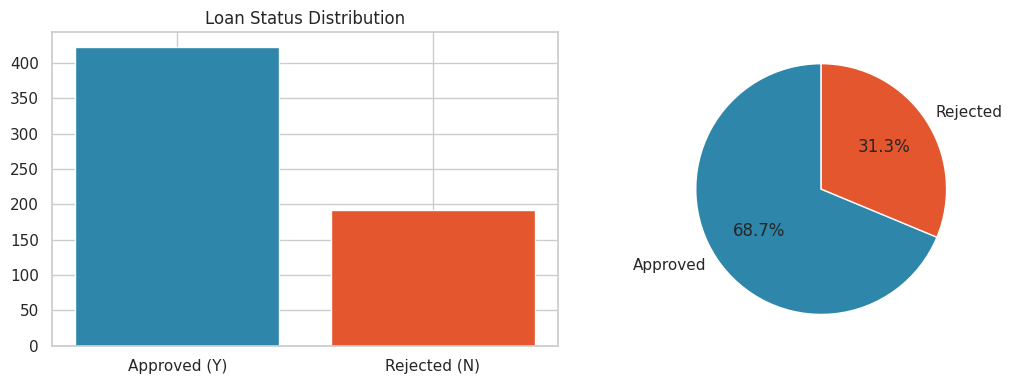

In [4]:
fig, ax = plt.subplots(1,2, figsize=(11,4))
counts = df['Loan_Status'].value_counts()
ax[0].bar(['Approved (Y)','Rejected (N)'], [counts['Y'], counts['N']], color=[BLUE, ORANGE]); ax[0].set_title('Loan Status Distribution')
ax[1].pie([counts['Y'], counts['N']], labels=['Approved','Rejected'], autopct='%1.1f%%', colors=[BLUE, ORANGE], startangle=90)
plt.tight_layout(); plt.show()

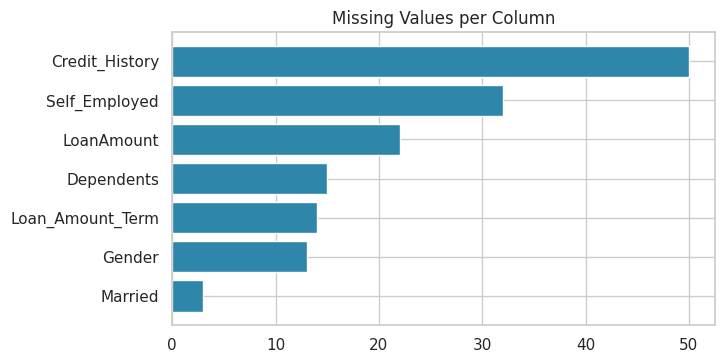

In [5]:
mv = missing[missing>0].sort_values()
plt.figure(figsize=(7,3.8)); plt.barh(mv.index, mv.values, color=BLUE); plt.title('Missing Values per Column'); plt.show()

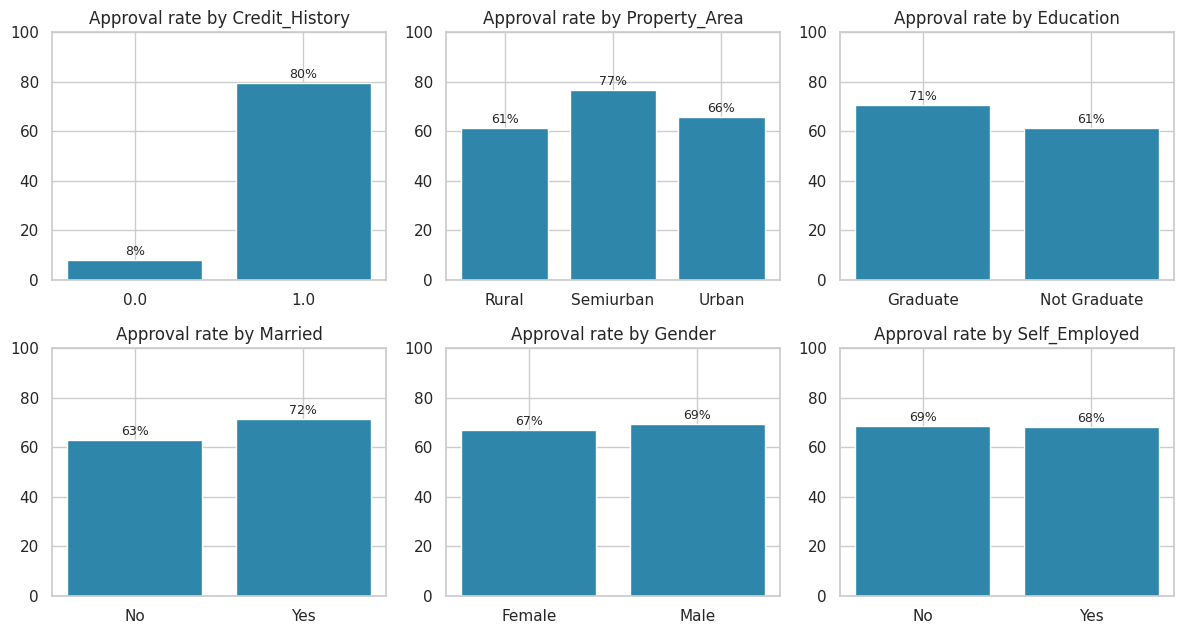

In [6]:
df['approved'] = (df['Loan_Status']=='Y').astype(int)
cats = ['Credit_History','Property_Area','Education','Married','Gender','Self_Employed']
fig, axes = plt.subplots(2,3, figsize=(12,6.5))
for a, col in zip(axes.ravel(), cats):
    r = df.groupby(col)['approved'].mean()*100
    a.bar([str(k) for k in r.index], r.values, color=BLUE); a.set_title('Approval rate by '+col); a.set_ylim(0,100)
    for i,v in enumerate(r.values): a.text(i, v+2, f'{v:.0f}%', ha='center', fontsize=9)
plt.tight_layout(); plt.show()

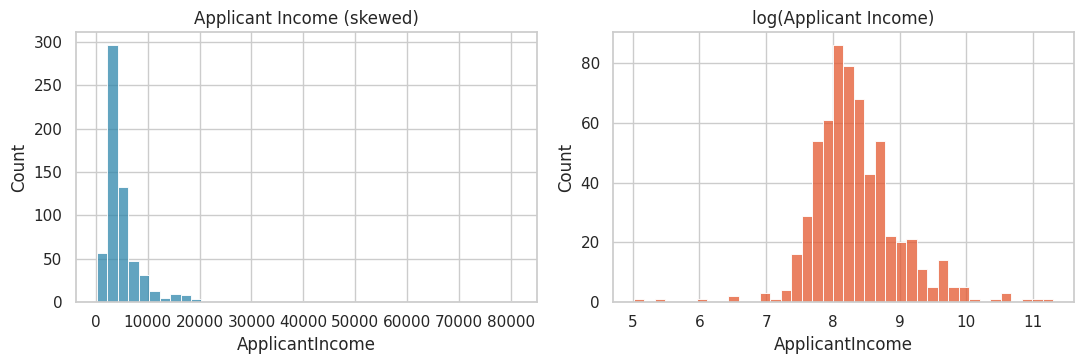

In [7]:
fig, ax = plt.subplots(1,2, figsize=(11,3.8))
sns.histplot(df['ApplicantIncome'], bins=40, color=BLUE, ax=ax[0]); ax[0].set_title('Applicant Income (skewed)')
sns.histplot(np.log1p(df['ApplicantIncome']), bins=40, color=ORANGE, ax=ax[1]); ax[1].set_title('log(Applicant Income)')
plt.tight_layout(); plt.show()

## 4. Feature engineering
New columns that describe affordability: total income, log values, monthly instalment (EMI) and income left after the EMI.

In [8]:
df = df.drop(columns=['Loan_ID','approved'])
df['Dependents'] = df['Dependents'].replace('3+','3').astype(float)
df['TotalIncome'] = df['ApplicantIncome'] + df['CoapplicantIncome']
df['TotalIncome_log'] = np.log1p(df['TotalIncome'])
df['LoanAmount_log'] = np.log1p(df['LoanAmount'])
df['EMI'] = df['LoanAmount'] / df['Loan_Amount_Term']
df['BalanceIncome'] = df['TotalIncome'] - df['EMI']*1000
y = (df['Loan_Status']=='Y').astype(int)
X = df.drop(columns=['Loan_Status'])
num_cols = ['ApplicantIncome','CoapplicantIncome','LoanAmount','Loan_Amount_Term','Dependents','TotalIncome_log','LoanAmount_log','EMI','BalanceIncome']
cat_cols = ['Gender','Married','Education','Self_Employed','Credit_History','Property_Area']
X.head()

,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,TotalIncome,TotalIncome_log,LoanAmount_log,EMI,BalanceIncome
0,Male,No,0.0,Graduate,No,5849,0.0,NaN,360.0,1.0,Urban,5849.0,8.674197,NaN,NaN,NaN
1,Male,Yes,1.0,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,6091.0,8.714732,4.859812,0.355556,5735.444444
2,Male,Yes,0.0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,3000.0,8.006701,4.204693,0.183333,2816.666667
3,Male,Yes,0.0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,4941.0,8.505525,4.795791,0.333333,4607.666667
4,Male,No,0.0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,6000.0,8.699681,4.955827,0.391667,5608.333333


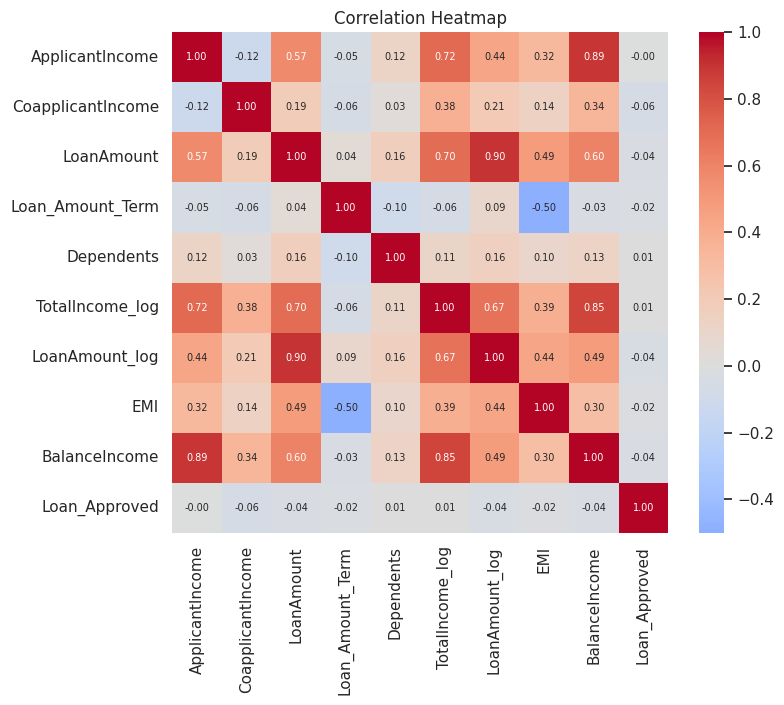

In [9]:
plt.figure(figsize=(8,6.5))
sns.heatmap(pd.concat([X[num_cols], y.rename('Loan_Approved')], axis=1).corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0, annot_kws={'size':7})
plt.title('Correlation Heatmap'); plt.show()

## 5. Train / test split (80% / 20%, stratified)

In [10]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
print('Train:', len(X_train), ' Test:', len(X_test))
print('Baseline (always predict Approved): %.4f' % max(y_test.mean(), 1-y_test.mean()))

Train: 491  Test: 123
Baseline (always predict Approved): 0.6911


## 6. Preprocessing pipeline
Missing numbers -> median, missing categories -> most frequent; numbers are scaled and categories one-hot encoded. Everything is fitted on training data only (no data leakage).

In [11]:
def make_pipe(clf):
    pre = ColumnTransformer([
        ('num', Pipeline([('imp', SimpleImputer(strategy='median')), ('sc', StandardScaler())]), num_cols),
        ('cat', Pipeline([('imp', SimpleImputer(strategy='most_frequent')), ('oh', OneHotEncoder(handle_unknown='ignore'))]), cat_cols)])
    return Pipeline([('pre', pre), ('clf', clf)])

## 7. Train six models and cross-validate

In [12]:
models = {
 'Logistic Regression': LogisticRegression(max_iter=1000),
 'KNN': KNeighborsClassifier(n_neighbors=11),
 'SVM (RBF)': SVC(probability=True, random_state=42),
 'Decision Tree': DecisionTreeClassifier(max_depth=4, random_state=42),
 'Random Forest': RandomForestClassifier(n_estimators=300, max_depth=5, min_samples_leaf=3, random_state=42),
 'Gradient Boosting': GradientBoostingClassifier(n_estimators=100, learning_rate=0.05, max_depth=2, random_state=42)}
skf = StratifiedKFold(5, shuffle=True, random_state=42)
fitted, preds, scores, rows = {}, {}, {}, []
def evaluate(name, pipe, cv_acc):
    yp = pipe.predict(X_test); s = pipe.predict_proba(X_test)[:,1]
    fitted[name], preds[name], scores[name] = pipe, yp, s
    rows.append({'Model':name,'CV_Accuracy':cv_acc,'Accuracy':accuracy_score(y_test,yp),'Precision':precision_score(y_test,yp),
                 'Recall':recall_score(y_test,yp),'F1':f1_score(y_test,yp),'ROC_AUC':roc_auc_score(y_test,s)})
for name, clf in models.items():
    pipe = make_pipe(clf)
    cv = cross_val_score(pipe, X_train, y_train, cv=skf, scoring='accuracy').mean()
    print('Training', name, '... CV accuracy = %.4f' % cv)
    pipe.fit(X_train, y_train); evaluate(name, pipe, cv)

Training Logistic Regression ... CV accuracy = 0.7962


Training KNN ... CV accuracy = 0.7311


Training SVM (RBF) ... CV accuracy = 0.7902
Training Decision Tree ... CV accuracy = 0.7739


Training Random Forest ... CV accuracy = 0.7942


Training Gradient Boosting ... CV accuracy = 0.7901


## 8. Hyper-parameter tuning (GridSearchCV)

In [13]:
grids = {
 'Random Forest (tuned)': (RandomForestClassifier(random_state=42), {'clf__n_estimators':[200,400],'clf__max_depth':[3,5,7],'clf__min_samples_leaf':[1,3,5]}),
 'Logistic Regression (tuned)': (LogisticRegression(max_iter=1000), {'clf__C':[0.01,0.1,1,10,100]})}
for name,(clf,grid) in grids.items():
    gs = GridSearchCV(make_pipe(clf), grid, cv=skf, scoring='accuracy', n_jobs=-1).fit(X_train, y_train)
    print(name, 'best parameters:', gs.best_params_, ' CV accuracy = %.4f' % gs.best_score_)
    evaluate(name, gs.best_estimator_, gs.best_score_)

Random Forest (tuned) best parameters: {'clf__max_depth': 3, 'clf__min_samples_leaf': 1, 'clf__n_estimators': 400}  CV accuracy = 0.7983


Logistic Regression (tuned) best parameters: {'clf__C': 0.1}  CV accuracy = 0.7983


## 9. Compare the models
The best model is chosen by **cross-validated accuracy** (more reliable than one small test set of 123 rows); F1 breaks ties.

In [14]:
res = pd.DataFrame(rows).sort_values(['CV_Accuracy','F1'], ascending=False).reset_index(drop=True)
display(res.round(4)); best_name = res.loc[0,'Model']; best = fitted[best_name]
print('Best model:', best_name)

,Model,CV_Accuracy,Accuracy,Precision,Recall,F1,ROC_AUC
0,Logistic Regression (tuned),0.7983,0.8618,0.8400,0.9882,0.9081,0.8542
1,Random Forest (tuned),0.7983,0.8537,0.8317,0.9882,0.9032,0.8492
2,Logistic Regression,0.7962,0.8537,0.8384,0.9765,0.9022,0.8576
3,Random Forest,0.7942,0.8374,0.8283,0.9647,0.8913,0.8334
4,SVM (RBF),0.7902,0.8455,0.8235,0.9882,0.8984,0.8238
5,Gradient Boosting,0.7901,0.8293,0.8265,0.9529,0.8852,0.8124
6,Decision Tree,0.7739,0.8455,0.8367,0.9647,0.8962,0.7678
7,KNN,0.7311,0.8211,0.8000,0.9882,0.8842,0.7635


Best model: Logistic Regression (tuned)


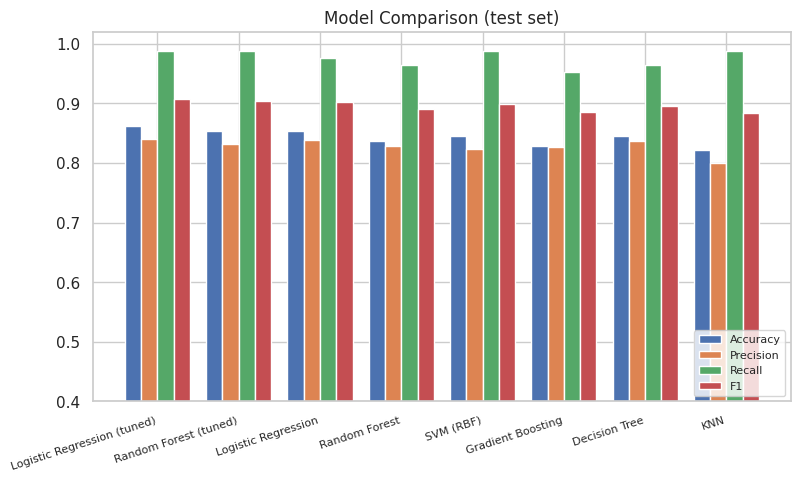

In [15]:
x = np.arange(len(res)); w = 0.2
plt.figure(figsize=(9,4.8))
for i,m in enumerate(['Accuracy','Precision','Recall','F1']): plt.bar(x+i*w, res[m], w, label=m)
plt.xticks(x+1.5*w, res['Model'], rotation=18, ha='right', fontsize=8); plt.ylim(0.4,1.02); plt.legend(loc='lower right', fontsize=8); plt.title('Model Comparison (test set)'); plt.show()

## 10. Detailed evaluation of the best model

              precision    recall  f1-score   support

    Rejected     0.9565    0.5789    0.7213        38
    Approved     0.8400    0.9882    0.9081        85

    accuracy                         0.8618       123
   macro avg     0.8983    0.7836    0.8147       123
weighted avg     0.8760    0.8618    0.8504       123



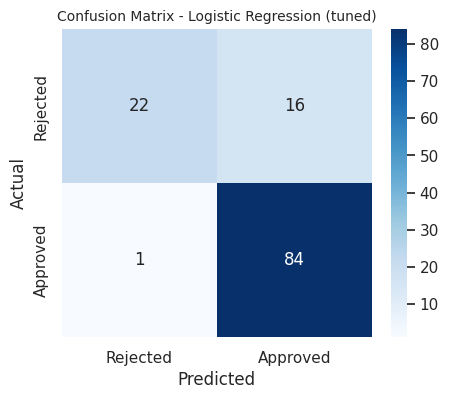

In [16]:
print(classification_report(y_test, preds[best_name], target_names=['Rejected','Approved'], digits=4))
cm = confusion_matrix(y_test, preds[best_name])
plt.figure(figsize=(5,4)); sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Rejected','Approved'], yticklabels=['Rejected','Approved'])
plt.title('Confusion Matrix - '+best_name, fontsize=10); plt.xlabel('Predicted'); plt.ylabel('Actual'); plt.show()

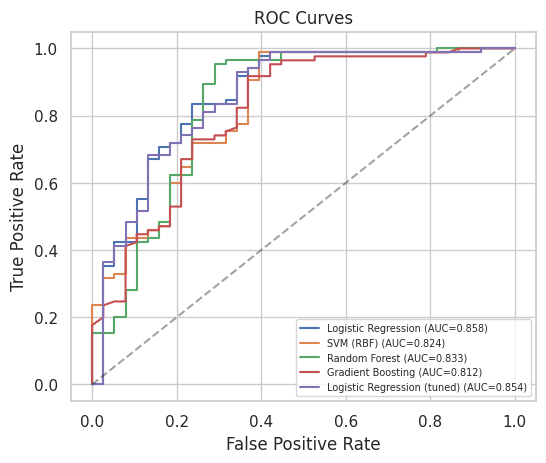

In [17]:
plt.figure(figsize=(6,4.8))
for n in ['Logistic Regression','SVM (RBF)','Random Forest','Gradient Boosting', best_name]:
    fpr,tpr,_ = roc_curve(y_test, scores[n]); plt.plot(fpr,tpr,label=f'{n} (AUC={roc_auc_score(y_test,scores[n]):.3f})')
plt.plot([0,1],[0,1],'k--',alpha=.4); plt.xlabel('False Positive Rate'); plt.ylabel('True Positive Rate'); plt.legend(fontsize=7); plt.title('ROC Curves'); plt.show()

In [18]:
cv_full = cross_val_score(best, X, y, cv=skf, scoring='accuracy')
print('5-fold CV accuracy on the full data:', cv_full.round(4), ' mean = %.4f' % cv_full.mean())

5-fold CV accuracy on the full data: [0.8211 0.813  0.7967 0.7561 0.8279]  mean = 0.8030


## 11. Which features matter most?

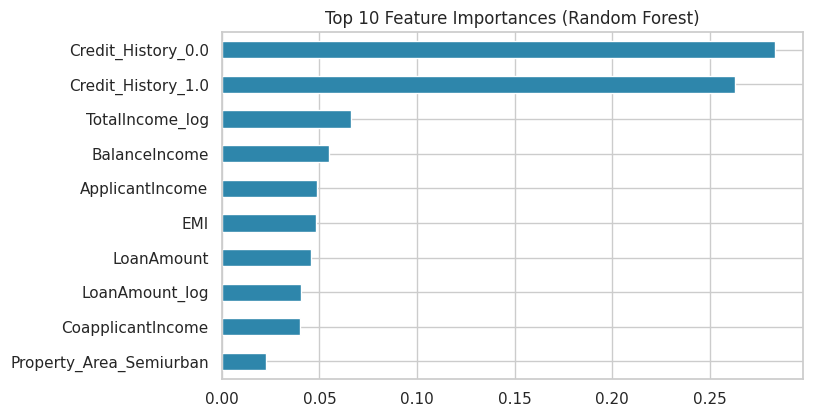

In [19]:
rf = fitted['Random Forest']
names = [n.replace('num__','').replace('cat__','') for n in rf.named_steps['pre'].get_feature_names_out()]
imp = pd.Series(rf.named_steps['clf'].feature_importances_, index=names).sort_values(ascending=False).head(10)
plt.figure(figsize=(7.5,4.5)); imp[::-1].plot.barh(color=BLUE); plt.title('Top 10 Feature Importances (Random Forest)'); plt.show()

## 12. Final prediction for new applicants

In [20]:
def predict_applicant(a):
    a = pd.DataFrame([a])
    a['Dependents'] = a['Dependents'].replace('3+','3').astype(float)
    a['TotalIncome'] = a['ApplicantIncome'] + a['CoapplicantIncome']
    a['TotalIncome_log'] = np.log1p(a['TotalIncome']); a['LoanAmount_log'] = np.log1p(a['LoanAmount'])
    a['EMI'] = a['LoanAmount']/a['Loan_Amount_Term']; a['BalanceIncome'] = a['TotalIncome'] - a['EMI']*1000
    p = best.predict_proba(a)[0,1]
    return ('APPROVED' if p>=0.5 else 'REJECTED'), p

samples = [
 ('Graduate, married, good credit, income 6000', dict(Gender='Male',Married='Yes',Dependents='1',Education='Graduate',Self_Employed='No',ApplicantIncome=6000,CoapplicantIncome=1500,LoanAmount=130,Loan_Amount_Term=360,Credit_History=1.0,Property_Area='Semiurban')),
 ('Same profile but bad credit history', dict(Gender='Male',Married='Yes',Dependents='1',Education='Graduate',Self_Employed='No',ApplicantIncome=6000,CoapplicantIncome=1500,LoanAmount=130,Loan_Amount_Term=360,Credit_History=0.0,Property_Area='Semiurban')),
 ('Low income, large loan, no credit record', dict(Gender='Female',Married='No',Dependents='0',Education='Not Graduate',Self_Employed='Yes',ApplicantIncome=1800,CoapplicantIncome=0,LoanAmount=250,Loan_Amount_Term=180,Credit_History=0.0,Property_Area='Rural')),
 ('High income, small loan, good credit', dict(Gender='Female',Married='Yes',Dependents='0',Education='Graduate',Self_Employed='No',ApplicantIncome=9000,CoapplicantIncome=3000,LoanAmount=120,Loan_Amount_Term=360,Credit_History=1.0,Property_Area='Urban'))]
print('FINAL PREDICTIONS'); print('-'*78)
for d,a in samples:
    lab,p = predict_applicant(a); print(f'[{lab:9s}] P(approve)={p:.2f}  {d}')

FINAL PREDICTIONS
------------------------------------------------------------------------------
[APPROVED ] P(approve)=0.84  Graduate, married, good credit, income 6000
[REJECTED ] P(approve)=0.38  Same profile but bad credit history
[REJECTED ] P(approve)=0.12  Low income, large loan, no credit record
[APPROVED ] P(approve)=0.78  High income, small loan, good credit


## 13. Conclusion
The tuned Logistic Regression gave about **86% test accuracy** and about **80% cross-validated accuracy**, against a 69% baseline.
**Credit history** is by far the most important feature. The model rarely rejects a good applicant but approves some risky ones (rejected-class recall is only about 58%), so a bank would raise the decision threshold.
Future work: more data, SMOTE / class weights, threshold tuning, XGBoost, SHAP explanations and a web app.